# 05 — Les variables du modèle : la couche gold

**Objectif.** Construire et expliquer la table que les modèles utiliseront : une ligne par heure-paire utilisable, la
cible (le PM2.5 de la station) et les **variables explicatives** (*features*), calculées sans jamais regarder la
référence ni le futur.

**Ce qu'on va voir.**

1. la couche gold et les plis de validation croisée par station ;
2. un modèle physique à deux paramètres (un gain et une hygroscopicité) ;
3. l'échelle logarithmique et le retour aux µg/m³ ;
4. les 48 variables, famille par famille, et leur lien avec l'erreur du capteur ;
5. la preuve qu'aucune variable ne regarde le futur ;
6. un bonus : un score de santé du capteur calculé à partir de ses seuls voisins.

**Comment le lire.** Chaque section part d'une question, montre le calcul, puis dit ce que nous observons, ce que ça
veut dire et ce que nous décidons. Commande : `python -m aircalib features`. Code : `src/aircalib/gold/build.py`,
`transform/{physics,features,neighbours}.py`.

**Vocabulaire de ce notebook.**

- **Couche gold** : la table finale, prête pour les modèles.
- **Zone d'apprentissage** : paires allemandes à 1,5 km ou moins, « saines » (horloge et variations vérifiées). Les
  paires invérifiables sont exclues de l'apprentissage et évaluées à part.
- **Pli** (*fold*) : une des 5 parts de la validation croisée. Une station et toutes ses paires (des deux bandes) sont
  dans un seul pli. Le modèle apprend sur 4 plis et est évalué sur le 5ᵉ.
- **Hors pli** : une valeur calculée pour une station avec des paramètres appris **sans** elle.
- **Fuite d'information** : une information disponible pendant l'évaluation mais pas en service réel (la référence, le
  futur, une station déjà vue) ; elle rend les scores trop beaux.

## 0. Préparation

Nous chargeons la table gold, la table des paires et les paramètres physiques ajustés par pli.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from aircalib.config import get_settings
from aircalib.evaluation.metrics import back_transform, bin_label, duan_smearing
from aircalib.schemas.gold import CATEGORICAL, FEATURES
from aircalib.transform import features as ft
from aircalib.transform.physics import fit_gain_kappa

SAMPLE = False
settings = get_settings().for_sample() if SAMPLE else get_settings()
G = settings.paths.gold
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(70)
pl.Config.set_tbl_cols(14)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
gold = pl.read_parquet(G / "pair_hours.parquet")
pairs = pl.read_parquet(G / "pairs.parquet")
fits = pl.read_parquet(G / "physics_fits.parquet")
train = gold.filter("training_zone")
size_mb = (G / "pair_hours.parquet").stat().st_size / 1e6
print(f"gold : {gold.height:,} heures-paires, {gold.width} colonnes, {size_mb:.0f} Mo")
print(f"zone d'entraînement : {train.height:,} heures")

gold : 13,822,352 heures-paires, 62 colonnes, 1165 Mo
zone d'entraînement : 4,674,183 heures


## 1. La couche gold et les plis par station

**Question.** Combien de données avons-nous pour apprendre, et les plis sont-ils équilibrés ?

**Ce que nous regardons.** Les heures par pays, bande et statut, puis les 5 plis. Les plis sont fixés **une fois pour
toutes** : chaque station allemande, de la plus grosse à la plus petite, va dans le pli le moins chargé. Les stations
françaises n'ont pas de pli : la France n'est jamais apprise.

In [2]:
print(
    gold.group_by("country", "distance_band", "sane_pair")
    .agg(heures=pl.len(), paires=pl.col("pair_id").n_unique())
    .sort("country", "distance_band", "sane_pair")
)
pairs.group_by("fold").agg(
    stations=pl.col("cv_group").n_unique(),
    paires=pl.len(),
    heures_entraînement=pl.col("training_hours").sum(),
    paires_far=(pl.col("distance_band") == "far").sum(),
).sort("fold")

shape: (8, 5)
┌─────────┬───────────────┬───────────┬─────────┬────────┐
│ country ┆ distance_band ┆ sane_pair ┆ heures  ┆ paires │
│ ---     ┆ ---           ┆ ---       ┆ ---     ┆ ---    │
│ str     ┆ str           ┆ bool      ┆ u32     ┆ u32    │
╞═════════╪═══════════════╪═══════════╪═════════╪════════╡
│ DE      ┆ far           ┆ false     ┆ 1166150 ┆ 139    │
│ DE      ┆ far           ┆ true      ┆ 5996395 ┆ 570    │
│ DE      ┆ near          ┆ false     ┆ 883988  ┆ 118    │
│ DE      ┆ near          ┆ true      ┆ 4674183 ┆ 459    │
│ FR      ┆ far           ┆ false     ┆ 212193  ┆ 32     │
│ FR      ┆ far           ┆ true      ┆ 482392  ┆ 64     │
│ FR      ┆ near          ┆ false     ┆ 58835   ┆ 12     │
│ FR      ┆ near          ┆ true      ┆ 348216  ┆ 37     │
└─────────┴───────────────┴───────────┴─────────┴────────┘


fold,stations,paires,heures_entraînement,paires_far
i32,u32,u32,u32,u32
null,58,145,0,96
0,48,245,989690,145
1,47,257,1033563,125
2,47,277,1003518,137
3,48,260,873842,156
4,47,247,773570,146


**Ce que nous observons.** La couche gold compte **13,82 millions d'heures-paires** (62 colonnes, 1,17 Go ; nombres
décimaux sur 32 bits, assez précis pour des µg/m³). La **zone d'apprentissage** fait **4,67 millions d'heures** sur 459
paires. Les 301 paires invérifiables (2,32 millions d'heures) restent dans la table, marquées `sane_pair = false`.
Chaque pli réunit 47 ou 48 stations allemandes et 0,77 à 1,03 million d'heures d'apprentissage, plus les paires `far`
de ses stations.

**Ce que ça veut dire.** Les plis sont de taille comparable ; chaque station n'est que dans un pli, quelle que soit
la distance de ses capteurs.

## 2. Un modèle physique à deux paramètres

### 2.1 Pourquoi la correction d'humidité classique aggraverait l'écart

**Question.** Peut-on corriger l'effet de l'humidité par la physique, avant tout apprentissage ?

**Le constat du notebook 04.** Le capteur brut **sous-estime** : rapport capteur / référence de 0,42 en air sec et
0,79 en air saturé. La correction classique (dite κ-Köhler) **divise** la mesure par un facteur de croissance
$C(\text{HR}) \ge 1$ : elle ferait encore baisser une valeur déjà trop basse. Elle n'est juste que si le capteur est
exact en air sec, ce qui n'est pas le cas.

**Décision : ajouter un gain.** Options : la correction classique seule (κ seul), un gain seul (sans humidité), ou les
deux ensemble. Nous retenons les deux :

$$
\mathrm{PM}_{\text{réf}} \approx a \cdot \frac{\mathrm{PM}_{\text{brut}}}{C(\mathrm{HR})}, \qquad
C = 1 + \frac{\kappa / \rho_p}{-1 + \dfrac{1}{a_w}}, \qquad a_w = \frac{\mathrm{HR}}{100}
$$

- $\mathrm{PM}_{\text{réf}}$ et $\mathrm{PM}_{\text{brut}}$ : PM2.5 de la station et du capteur (µg/m³) ;
- $a$ : le **gain**, ce que le capteur rate en air sec (il ne voit que $1/a$ de la référence) ;
- $C$ : le facteur de croissance des particules par l'eau ;
- $\kappa$ : l'**hygroscopicité**, la capacité des particules à absorber l'eau (0 = aucune) ;
- $\rho_p$ : rapport de densité particule / eau, fixé à 1,65 (seul $\kappa/\rho_p$ peut être estimé) ;
- HR : l'humidité relative **officielle** en % ; $a_w$ : la même, entre 0 et 1.

En logarithme, la relation devient une somme :

$$
\ln \mathrm{PM}_{\text{réf}} = \ln a + \ln \mathrm{PM}_{\text{brut}} - \ln C(\mathrm{HR};\kappa)
$$

Pour un $\kappa$ donné, le meilleur $\ln a$ est la moyenne des résidus ; nous cherchons donc $\kappa$ par une recherche
à une dimension. $a$ et $\kappa$ sont ajustés **sur l'apprentissage uniquement** : une fois par pli (sans la station
testée), et une fois sur toute la zone d'apprentissage (pour la France).

In [3]:
fits.with_columns(
    rapport_sec=(1 / pl.col("gain")).round(3),
    gain_par_humidité=((pl.col("mse_log_no_growth") - pl.col("mse_log")) / pl.col("mse_log_no_growth")).round(
        3
    ),
).select("fold", "gain", "kappa", "rapport_sec", "mse_log", "mse_log_no_growth", "gain_par_humidité", "n")

fold,gain,kappa,rapport_sec,mse_log,mse_log_no_growth,gain_par_humidité,n
i32,f64,f64,f64,f64,f64,f64,i64
0,2.470456,0.063642,0.405,0.480102,0.508773,0.056,3684493
1,2.343024,0.067505,0.427,0.457227,0.488125,0.063,3640620
2,2.384163,0.064414,0.419,0.502914,0.53135,0.054,3670665
3,2.335305,0.066801,0.428,0.482403,0.512588,0.059,3800341
4,2.433726,0.066136,0.411,0.500699,0.531072,0.057,3900613
-1,2.392638,0.065649,0.418,0.48551,0.51519,0.058,4674183


### 2.2 Le plafond d'humidité

**Question.** $C$ devient infini quand l'humidité atteint 100 %. Il faut plafonner l'humidité : à quelle valeur, et
qu'est-ce que ce choix change ?

**Ce que nous regardons.** Le même ajustement sur toute la zone d'apprentissage avec quatre plafonds : 90, 95, 97 et
99 %.

In [4]:
ok = train.drop_nulls(["log_pm25", "log_reference", "official_humidity"])
rows = []
for cap in (90.0, 95.0, 97.0, 99.0):
    cfg = settings.physics.model_copy(update={"rh_cap_pct": cap})
    fit = fit_gain_kappa(
        ok["log_pm25"].to_numpy(), ok["log_reference"].to_numpy(), ok["official_humidity"].to_numpy(), cfg
    )
    rows.append(
        {
            "plafond_HR": cap,
            "gain_a": round(fit.gain, 3),
            "kappa": round(fit.kappa, 4),
            "mse_ln": round(fit.mse_log, 4),
        }
    )
pl.DataFrame(rows)

plafond_HR,gain_a,kappa,mse_ln
f64,f64,f64,f64
90.0,2.598,0.1263,0.4847
95.0,2.393,0.0656,0.4855
97.0,2.291,0.0442,0.4885
99.0,2.144,0.0205,0.4969


**Ce que nous observons.** $\kappa$ dépend fortement du plafond (0,126 à 90 %, 0,066 à 95 %, 0,044 à 97 %, 0,021 à
99 %), mais l'erreur en log change à peine entre 90 et 95 % (0,4847 contre 0,4855) et se dégrade au-delà (0,4969 à
99 %).

**Décision : plafond à 95 %** (`physics.rh_cap_pct`). Au-delà, les hygromètres officiels ont une incertitude de 2 à 3
points et la loi prédit une croissance que les données ne montrent pas. Ce que nous acceptons : $\kappa$ est un
paramètre **effectif**, lié à ce plafond, et non une propriété physique de l'aérosol.

### 2.3 La courbe ajustée face au rapport observé

**Question.** Le modèle à deux paramètres reproduit-il l'effet de l'humidité vu au notebook 04 ?

**Ce que nous regardons.** Le rapport prédit capteur / référence, $C(\mathrm{HR}) / a$, contre le rapport médian observé
par tranche d'humidité ; puis le rapport qui reste après correction physique hors pli.

tranche,hr_médiane,rapport_observé,après_physique,heures,rapport_modèle
str,f32,f32,f32,u32,f64
"""0. < 50 %""",42.0,0.41179,0.956756,395144,0.43
"""1. 50–60 %""",55.0,0.430273,0.981362,356418,0.438
"""2. 60–70 %""",65.0,0.461489,1.02826,498052,0.449
"""3. 70–80 %""",75.0,0.507917,1.08522,737821,0.468
"""4. 80–90 %""",85.0,0.589854,1.150141,975695,0.512
"""5. 90–95 %""",92.0,0.685476,1.11322,570860,0.609
"""6. ≥ 95 %""",97.0,0.792242,1.078503,537805,0.734


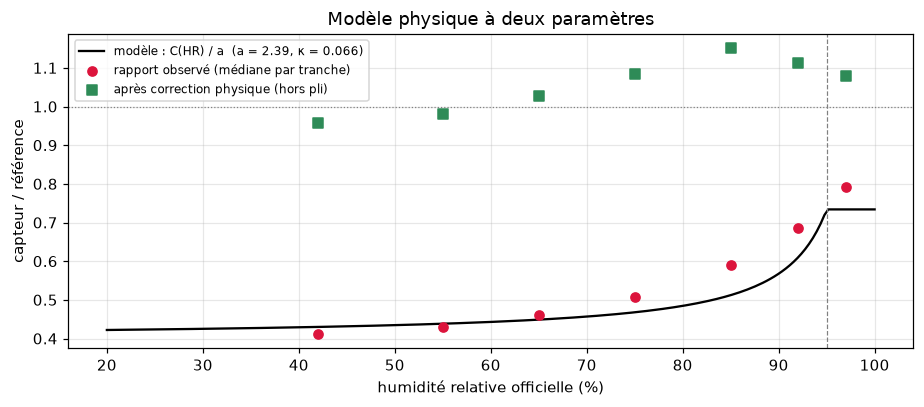

In [5]:
all_fit = fits.filter(pl.col("fold") == -1).row(0, named=True)
edges = settings.evaluation.humidity_bins
positive = (pl.col("reference") > 1) & (pl.col("pm25_mean") > 1)
observed = (
    train.filter(positive)
    .with_columns(tranche=bin_label(pl.col("official_humidity"), edges, " %"))
    .group_by("tranche")
    .agg(
        hr_médiane=pl.col("official_humidity").median(),
        rapport_observé=(pl.col("pm25_mean") / pl.col("reference")).median(),
        après_physique=(pl.col("physics_pm25") / pl.col("reference")).median(),
        heures=pl.len(),
    )
    .sort("tranche")
)
cap = settings.physics.rh_cap_pct
rh = np.linspace(20, 100, 200)
aw = np.minimum(rh, cap) / 100
curve = (1 + all_fit["kappa"] / settings.physics.density_ratio * aw / (1 - aw)) / all_fit["gain"]
observed = observed.with_columns(
    rapport_modèle=pl.col("hr_médiane").map_elements(
        lambda h: float(
            (
                1
                + all_fit["kappa"]
                / settings.physics.density_ratio
                * min(h, cap)
                / 100
                / (1 - min(h, cap) / 100)
            )
            / all_fit["gain"]
        ),
        return_dtype=pl.Float64,
    )
)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(
    rh, curve, color="k", label=f"modèle : C(HR) / a  (a = {all_fit['gain']:.2f}, κ = {all_fit['kappa']:.3f})"
)
ax.scatter(
    observed["hr_médiane"],
    observed["rapport_observé"],
    color="crimson",
    zorder=3,
    label="rapport observé (médiane par tranche)",
)
ax.scatter(
    observed["hr_médiane"],
    observed["après_physique"],
    color="seagreen",
    marker="s",
    zorder=3,
    label="après correction physique (hors pli)",
)
ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.axvline(cap, color="grey", lw=0.8, ls="--")
ax.set_xlabel("humidité relative officielle (%)")
ax.set_ylabel("capteur / référence")
ax.set_title("Modèle physique à deux paramètres")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_modele_physique.png")
observed.with_columns(pl.col(pl.Float64).round(3))

**Ce que nous observons.** Sur les 5 plis, le gain va de **2,34 à 2,47** et $\kappa$ de **0,064 à 0,068** (sur toute
la zone : $a = 2{,}39$, $\kappa = 0{,}066$). $1/a = 0{,}42$ : en air sec, le capteur voit 42 % de la référence,
exactement le rapport mesuré au notebook 04. Le modèle prédit 0,43 en air sec et 0,73 à 97 %, contre 0,41 et 0,79
observés ; mais la loi reste plate jusqu'à 80 % puis monte d'un coup, alors que le rapport observé monte dès 60 %.
Après correction physique, le rapport médian passe de 0,41–0,79 à **0,96–1,15** selon l'humidité.

**Ce que ça veut dire.** Les paramètres sont stables d'un pli à l'autre et le gain est physiquement plausible.
$\kappa$ est plus bas que les valeurs publiées pour l'aérosol continental (0,1 à 0,4, Petters et Kreidenweis, 2007) :
c'est un $\kappa$ **effectif**, qui mêle trois effets probables (hypothèses) : le capteur chauffe l'air qu'il aspire,
l'humidité vient d'une station à environ 6 km, et la réponse optique du SDS011 ne suit pas toute la croissance des
particules. L'humidité n'améliore l'erreur en log que de 6 % par rapport au gain seul : l'essentiel de l'erreur vient
du bruit horaire et des différences entre capteurs.

**Décision.** Le modèle physique ne sera pas le produit, mais une **variable** du modèle appris (calculée hors pli).

## 3. L'échelle logarithmique et le retour aux µg/m³

**Question.** L'erreur est multiplicative (notebook 04) : un modèle pourrait apprendre en logarithme. Comment revenir
ensuite aux µg/m³ sans biais ?

**Ce que nous regardons.** La cible et le PM brut ont une version logarithmique avec un **plancher** de 1 µg/m³ :
$\ln(\max(x, 1))$, où $x$ est la concentration. Sous 1 µg/m³, la référence est au niveau de son bruit (valeurs
négatives validées), et le logarithme donnerait un poids énorme à ce bruit.

Un modèle appris en log prédit la **médiane** ; revenir par $e^{\hat y}$ sous-estime la **moyenne** dès que les erreurs
sont dispersées. La **correction de Duan** (1983) multiplie par la moyenne des exponentielles des résidus
d'apprentissage :

$$
\widehat{\mathrm{PM}} = e^{\hat y} \cdot \frac{1}{n} \sum_{i \in \text{apprentissage}} e^{\,y_i - \hat y_i}
$$

où $\hat y$ est la prédiction en log, $y_i$ et $\hat y_i$ la cible et la prédiction en log de la ligne $i$
d'apprentissage, et $n$ le nombre de ces lignes. Nous la testons sur le modèle physique seul (pente fixée à 1 en log),
puis sur un modèle log-linéaire à pente libre appris hors pli.

In [6]:
floor = settings.features.log_floor_ugm3
print(
    train.select(
        capteur_sous_plancher=(pl.col("pm25_mean") < floor).mean().round(3),
        référence_sous_plancher=(pl.col("reference") < floor).mean().round(4),
    )
)
# (a) Physical model alone (slope 1 in log): its residuals depend strongly on the level (see section 4).
smearing = duan_smearing(train["log_reference"] - train["log_physics_pm25"])
print(f"modèle physique seul : facteur de Duan {smearing:.3f}")
print(
    train.select(
        référence_moyenne=pl.col("reference").mean(),
        exp_sans_correction=back_transform(pl.col("log_physics_pm25"), 1.0).mean(),
        exp_avec_duan=back_transform(pl.col("log_physics_pm25"), smearing).mean(),
    )
)
# (b) Free-slope log-linear model, ln ref = b0 + b1 ln(physics), learned out of fold; smearing on training.
rows = []
for fold in range(settings.cv.n_folds):
    fit_on, test_on = train.filter(pl.col("fold") != fold), train.filter(pl.col("fold") == fold)
    x, y = (
        fit_on["log_physics_pm25"].to_numpy().astype(float),
        fit_on["log_reference"].to_numpy().astype(float),
    )
    b1 = float(np.cov(x, y)[0, 1] / x.var())
    b0 = float(y.mean() - b1 * x.mean())
    factor = duan_smearing(pl.Series(y - (b0 + b1 * x)))
    prediction = b0 + b1 * pl.col("log_physics_pm25")
    rows.append(
        test_on.select(
            pli=pl.lit(fold),
            pente_log=pl.lit(round(b1, 3)),
            facteur_duan=pl.lit(round(factor, 3)),
            référence_moyenne=pl.col("reference").mean(),
            exp_sans_correction=back_transform(prediction, 1.0).mean(),
            exp_avec_duan=back_transform(prediction, factor).mean(),
        )
    )
pl.concat(rows).with_columns(pl.col(pl.Float32, pl.Float64).round(2))

shape: (1, 2)
┌───────────────────────┬─────────────────────────┐
│ capteur_sous_plancher ┆ référence_sous_plancher │
│ ---                   ┆ ---                     │
│ f64                   ┆ f64                     │
╞═══════════════════════╪═════════════════════════╡
│ 0.124                 ┆ 0.0057                  │
└───────────────────────┴─────────────────────────┘
modèle physique seul : facteur de Duan 1.501
shape: (1, 3)
┌───────────────────┬─────────────────────┬───────────────┐
│ référence_moyenne ┆ exp_sans_correction ┆ exp_avec_duan │
│ ---               ┆ ---                 ┆ ---           │
│ f32               ┆ f32                 ┆ f32           │
╞═══════════════════╪═════════════════════╪═══════════════╡
│ 9.423869          ┆ 11.796103           ┆ 17.711061     │
└───────────────────┴─────────────────────┴───────────────┘


pli,pente_log,facteur_duan,référence_moyenne,exp_sans_correction,exp_avec_duan
i32,f64,f64,f32,f32,f32
0,0.47,1.17,9.01,9.0,10.55
1,0.49,1.16,9.71,7.79,9.08
2,0.47,1.18,9.53,8.14,9.57
3,0.48,1.17,9.58,7.49,8.75
4,0.47,1.17,9.24,8.43,9.88


**Ce que nous observons.** 12,4 % des heures du capteur et 0,6 % des heures de référence sont sous le plancher. Sur le
modèle physique seul, la correction de Duan **aggrave** la moyenne (9,4 µg/m³ réels ; 11,8 sans correction ; 17,7
avec). Sur un modèle log-linéaire à **pente libre**, la pente vaut **0,47** et la correction fait ce qu'on attend : la
moyenne prédite passe de 8,2 à 9,6 µg/m³, pour une référence de 9,4.

**Ce que ça veut dire.** La correction de Duan suppose un modèle dont les résidus ne dépendent pas du niveau : ce n'est
pas le cas du modèle physique, dont la pente est imposée. La pente de 0,47 montre une forte **régression vers la
moyenne** : quand le capteur lit haut, une partie de l'écart est du bruit, ce qu'un modèle à pente 1 ne peut pas
corriger.

**Décision.** Duan est appliqué pli par pli, sur les seuls résidus d'apprentissage, et uniquement aux modèles à pente
libre appris en log. Le choix entre log et µg/m³ sera fait au notebook 06 sur les mêmes plis.

## 4. Les variables, famille par famille

**Question.** Quelles informations donner au modèle, et lesquelles sont liées à l'erreur du capteur ?

**Ce que nous regardons.** Pour chaque variable, sa définition et sa corrélation de rang (Spearman) avec **l'erreur à
corriger**, $\ln \mathrm{PM}_{\text{réf}} - \ln \mathrm{PM}_{\text{brut}}$ (le facteur multiplicatif qui manque au
capteur), sur la zone d'apprentissage. Une corrélation de rang ne voit pas les interactions : c'est un premier tri,
pas un verdict (le verdict viendra de l'ablation, notebook 06).

| famille | variables | définition et raison |
|---|---|---|
| capteur brut | `pm25_mean`, `pm25_median`, `pm25_std`, `pm10_mean`, `n_valid`, `completeness`, `pm25_pm10_ratio`, `log_pm25` | statistiques de l'heure ; le rapport PM2.5/PM10 renseigne sur la taille des particules ; l'écart-type et le nombre de mesures disent si l'heure est stable |
| météo officielle | `official_humidity`, `official_temperature`, `dew_point`, `dew_point_depression`, `sensor_weather_km`, `weather_fallback` | humidité et température de la station météo la plus proche du capteur ; **point de rosée** $T_d$ (température à laquelle l'air serait saturé), formule de Magnus ; l'écart $T - T_d$ mesure la distance au brouillard |
| sonde locale (secondaire) | `local_humidity`, `local_temperature`, `local_reliable` | humidité de la sonde du capteur quand elle est fiable (environ 27 % des heures) |
| modèle physique | `kohler_c`, `physics_pm25`, `log_physics_pm25` | $C(\mathrm{HR})$ et l'estimation $a\,\mathrm{PM}/C$, **hors pli** |
| temps | `hour_*`, `weekday_*`, `month_*` (sinus, cosinus) | heure locale, jour, mois ; le codage $(\sin 2\pi t/T, \cos 2\pi t/T)$ rend 23 h proche de 0 h et décembre proche de janvier |
| dynamique (passé) | `pm25_{mean,std}_{3,6,24}h`, `humidity_{mean,std}_{3,6,24}h` | moyennes et écarts-types glissants sur les heures $(h-w, h]$ du même capteur : un pic isolé et un épisode durable ne se corrigent pas pareil |
| capteur | `age_years`, `missing_rate_24h`, `missing_rate_168h` | âge estimé ; part des 24 h / 7 jours **précédents** sans mesure valide |
| contexte | `distance_km`, `station_type`, `station_area`, `method_class` | distance capteur–station, type et environnement de la station, famille d'instrument de la référence |
| voisinage citoyen | `neighbour_median`, `n_neighbours`, `neighbour_log_ratio` | médiane des autres capteurs citoyens à 3 km ou moins à la même heure (au moins 3), et l'écart $\ln \mathrm{PM} - \ln \text{médiane}$ ; **jamais la référence** |

In [7]:
numeric = [c for family in FEATURES.values() for c in family if c not in CATEGORICAL]
sample = train.sample(n=min(1_000_000, train.height), seed=0).with_columns(
    error=pl.col("log_reference") - pl.col("log_pm25")
)
rows = []
for family, columns in FEATURES.items():
    for column in columns:
        if column in CATEGORICAL:
            spread = (
                sample.group_by(column)
                .agg(pl.col("error").median())
                .select(pl.col("error").max() - pl.col("error").min())
                .item()
            )
            rows.append(
                {
                    "famille": family,
                    "variable": column,
                    "spearman_avec_erreur": None,
                    "écart_entre_catégories": round(spread, 3),
                    "manquants_%": round(100 * sample[column].null_count() / sample.height, 1),
                }
            )
        else:
            rho = sample.select(pl.corr(pl.col(column).cast(pl.Float64), "error", method="spearman")).item()
            rows.append(
                {
                    "famille": family,
                    "variable": column,
                    "spearman_avec_erreur": None if rho is None else round(rho, 3),
                    "écart_entre_catégories": None,
                    "manquants_%": round(100 * sample[column].null_count() / sample.height, 1),
                }
            )
links = pl.DataFrame(rows)
links

famille,variable,spearman_avec_erreur,écart_entre_catégories,manquants_%
str,str,f64,f64,f64
"""capteur brut""","""pm25_mean""",-0.643,null,0.0
"""capteur brut""","""pm25_median""",-0.63,null,0.0
"""capteur brut""","""pm25_std""",-0.497,null,0.0
"""capteur brut""","""pm10_mean""",-0.558,null,0.0
"""capteur brut""","""n_valid""",0.05,null,0.0
"""capteur brut""","""completeness""",-0.016,null,0.0
"""capteur brut""","""pm25_pm10_ratio""",-0.216,null,0.0
"""capteur brut""","""log_pm25""",-0.642,null,0.0
"""météo officielle""","""official_humidity""",-0.313,null,0.0


**Ce que nous observons.**

- **L'écart aux voisins citoyens** est la variable la plus liée à l'erreur (**−0,65**) : un capteur qui lit plus haut
  que ses voisins se trompe vers le haut. Elle est disponible pour 79 % des heures (au moins 3 voisins valides).
- **Le niveau du capteur** (−0,64) et ses moyennes glissantes (−0,59 à −0,63), puis l'écart-type horaire (−0,50).
- **L'humidité** (−0,31), la distance à la saturation $T - T_d$ (+0,31) et le facteur $C$ (−0,31).
- L'âge du capteur (−0,19), le mois et la température (0,13 à 0,18).
- **Presque pas liées** : la distance capteur–station (−0,01), la distance à la station météo (0,02), les taux de
  mesures manquantes.

**Ce que ça veut dire.** Plus le capteur lit haut, plus il surestime relativement (la régression vers la moyenne de la
section 3). Les voisins citoyens apportent une information que la physique n'a pas : l'état de l'air autour, mesuré
par des capteurs du même type.

**Décision.** Les 48 variables entrent toutes dans le modèle ; c'est l'ablation (notebook 06) qui dira lesquelles
comptent vraiment. Limite : les voisins sont seulement les capteurs téléchargés pour ce projet.

## 5. Aucune variable ne regarde le futur

**Question.** Les moyennes glissantes peuvent, par une erreur d'indice, inclure une heure future. Ce serait une fuite
d'information : le modèle aurait en évaluation une information qu'il n'aura jamais en service, et ses scores seraient
trop beaux.

**Ce que nous regardons.** Sur une vraie paire, nous calculons les variables dynamiques, puis nous **remplaçons toutes
les valeurs après une heure $t$** par des valeurs absurdes et nous recalculons.

> **🔎 Contrôle — le test anti-fuite.** Si aucune variable ne regarde le futur, les variables jusqu'à $t$ doivent être
> strictement identiques avant et après la modification. Le même contrôle, sur des données inventées, est un test
> automatique (`test_no_feature_uses_the_future`), relancé à chaque exécution des tests.

In [8]:
f = settings.features
one_pair = pairs.sort("usable_hours", descending=True)["pair_id"][0]
series = (
    pl.read_parquet(
        settings.paths.silver / "pairs" / "pair_hours.parquet",
        columns=["pair_id", "hour", "hour_flag", "pm25_mean"],
    )
    .filter(pl.col("pair_id") == one_pair)
    .sort("hour")
    .with_columns(valid=pl.col("hour_flag") == "ok")
)


def dynamic(frame):
    return frame.with_columns(
        *ft.rolling_past("pm25_mean", f.rolling_hours), *ft.missing_rate_past("valid", f.missing_window_hours)
    )


cut = series["hour"][series.height // 2]
altered = series.with_columns(
    pm25_mean=pl.when(pl.col("hour") > cut).then(pl.lit(9999.0)).otherwise("pm25_mean"),
    valid=pl.when(pl.col("hour") > cut).then(pl.lit(False)).otherwise("valid"),
)
before = dynamic(series).filter(pl.col("hour") <= cut)
after = dynamic(altered).filter(pl.col("hour") <= cut)
print(f"paire {one_pair} : {series.height} heures, coupure au {cut}")
print("variables identiques jusqu'à la coupure :", before.equals(after))
print(
    "et différentes après (le test peut échouer) :",
    not dynamic(series).filter(pl.col("hour") > cut).equals(dynamic(altered).filter(pl.col("hour") > cut)),
)

paire 1178-1 : 17177 heures, coupure au 2024-12-29 02:00:00
variables identiques jusqu'à la coupure : True
et différentes après (le test peut échouer) : True


**Ce que nous observons.** Sur la paire la plus longue (17 177 heures), les variables calculées avant et après avoir
rendu absurdes toutes les valeurs postérieures au 29/12/2024 sont **strictement identiques** jusqu'à cette date
(`True`), et différentes après.

**Ce que ça veut dire.** Aucune variable dynamique ne regarde le futur.

## 6. Bonus : la santé d'un capteur, sans station officielle

**Question.** Un réseau de capteurs peut-il repérer lui-même ses capteurs en panne, sans station officielle à côté ?

**Ce que nous regardons.** Pour chaque paire, sur les heures où au moins 3 voisins sont valides, la corrélation des
**variations horaires** de $\ln \mathrm{PM}$ du capteur avec celles de la médiane de ses voisins
(`health_change_corr`). Nous regardons si ce score, **calculé sans aucune donnée de station**, retrouve les paires
invérifiables (qui, elles, ont été repérées grâce à la station). Pour résumer la séparation, nous utilisons l'**AUC** :
la probabilité qu'un capteur abîmé tiré au hasard ait un moins bon score qu'un capteur sain tiré au hasard (0,5 =
hasard, 1 = séparation parfaite).

paires avec assez d'heures de voisinage : 999 sur 1431 (156 invérifiables)
{'AUC variations': 0.895, 'AUC niveaux': 0.912}
shape: (5, 5)
┌───────┬───────────┬──────────────────────┬───────────┬────────┐
│ seuil ┆ signalées ┆ vraies_invérifiables ┆ précision ┆ rappel │
│ ---   ┆ ---       ┆ ---                  ┆ ---       ┆ ---    │
│ f64   ┆ i64       ┆ i64                  ┆ f64       ┆ f64    │
╞═══════╪═══════════╪══════════════════════╪═══════════╪════════╡
│ 0.05  ┆ 35        ┆ 33                   ┆ 0.943     ┆ 0.212  │
│ 0.1   ┆ 69        ┆ 58                   ┆ 0.841     ┆ 0.372  │
│ 0.15  ┆ 96        ┆ 77                   ┆ 0.802     ┆ 0.494  │
│ 0.2   ┆ 119       ┆ 87                   ┆ 0.731     ┆ 0.558  │
│ 0.3   ┆ 163       ┆ 99                   ┆ 0.607     ┆ 0.635  │
└───────┴───────────┴──────────────────────┴───────────┴────────┘


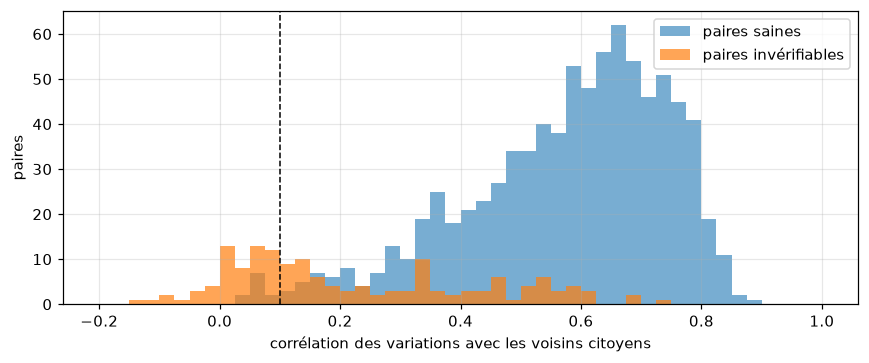

In [9]:
scored = pairs.filter(pl.col("health_change_corr").is_not_null()).with_columns(broken=~pl.col("sane_pair"))
n_broken = scored["broken"].sum()
print(
    f"paires avec assez d'heures de voisinage : {scored.height} sur {pairs.height} ({n_broken} invérifiables)"
)


def auc(score: np.ndarray, label: np.ndarray) -> float:
    ranks = np.empty(len(score))
    ranks[score.argsort()] = np.arange(1, len(score) + 1)
    n1, n0 = label.sum(), len(label) - label.sum()
    return float((ranks[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


label = scored["broken"].to_numpy()
print(
    {
        name: round(auc(-scored[col].to_numpy(), label), 3)
        for name, col in (("AUC variations", "health_change_corr"), ("AUC niveaux", "health_level_corr"))
    }
)
rows = []
for threshold in (0.05, 0.1, 0.15, 0.2, 0.3):
    flagged = scored["health_change_corr"].to_numpy() < threshold
    tp = int((flagged & label).sum())
    rows.append(
        {
            "seuil": threshold,
            "signalées": int(flagged.sum()),
            "vraies_invérifiables": tp,
            "précision": round(tp / max(flagged.sum(), 1), 3),
            "rappel": round(tp / label.sum(), 3),
        }
    )
print(pl.DataFrame(rows))
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(-0.2, 1, 49)
ax.hist(scored.filter(~pl.col("broken"))["health_change_corr"], bins=bins, alpha=0.6, label="paires saines")
ax.hist(
    scored.filter(pl.col("broken"))["health_change_corr"], bins=bins, alpha=0.7, label="paires invérifiables"
)
ax.axvline(settings.health.change_corr_min, color="k", ls="--", lw=1)
ax.set_xlabel("corrélation des variations avec les voisins citoyens")
ax.set_ylabel("paires")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_sante_capteurs.png")

**Ce que nous observons.** Sur les 999 paires qui ont assez d'heures avec au moins 3 voisins (dont 156 invérifiables),
le score sépare les deux groupes avec une **AUC de 0,90**. Au seuil 0,1 (par analogie avec le contrôle d'horloge),
**69 paires sont signalées, dont 58 réellement invérifiables : précision 84 %, rappel 37 %**. Au seuil 0,2 : précision
73 %, rappel 56 %.

**Ce que ça veut dire.** Le voisinage citoyen suffit à repérer une partie des capteurs en panne. Limites : le score
n'existe que là où il y a au moins 3 voisins (999 paires sur 1 431), et ce seuil a été choisi en regardant toutes les
paires ; le notebook 06 le valide sur des stations tenues à l'écart (précision 65 %, rappel 56 %).

## Ce qu'il faut retenir

- **Couche gold** : 13,82 millions d'heures-paires, dont **4,67 millions** pour apprendre (459 paires saines) ; 5 plis
  de 47–48 stations, une station n'étant jamais dans deux plis.
- **Modèle physique** : $a = 2{,}39$ (le capteur voit 42 % de la référence en air sec), $\kappa = 0{,}066$, stables
  d'un pli à l'autre ; il ramène le rapport capteur / référence de 0,41–0,79 à 0,96–1,15. Humidité plafonnée à 95 %.
- **48 variables** en 9 familles ; la plus liée à l'erreur est l'écart aux voisins citoyens (corrélation de rang
  −0,65).
- 🔎 **Aucune variable ne regarde le futur** : vérifié sur une vraie paire de 17 177 heures et par un test automatique.
- **Bonus** : un score de santé calculé sans station retrouve les capteurs défectueux avec une AUC de 0,90.